In [5]:

from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

ROOT = Path.cwd()
RAW_DATA_ROOT = ROOT / "runs"

STRATEGIES = {
    "EIG": {
        "metrics": ROOT / "maze_metric_outputs_basic",
        "raw": RAW_DATA_ROOT / "REWARD_DRIVEN_1000",
        "prefix": "REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_",
    },
    "Count-based": {
        "metrics": ROOT / "maze_metric_outputs_count",
        "raw": RAW_DATA_ROOT / "COUNT_REWARD_DRIVEN_1000",
        "prefix": "COUNT_REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_",
    },
    "Random": {
        "metrics": ROOT / "maze_metric_outputs_random",
        "raw": RAW_DATA_ROOT / "RANDOM_REWARD_DRIVEN_1000",
        "prefix": "RANDOM_REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_",
    },
}

FIG5_DIR = ROOT / "paper_figures" / "figure_5"
FIG5_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = (0.2, 0.3)
SEEDS_COMPARE = [str(i) for i in range(10)]

STRATEGY_COLORS = {
    "EIG": "#18545D",
    "Count-based": "#A6533D",
    "Random": "#66737A",
}

STRATEGY_MARKERS = {
    "EIG": "o",
    "Count-based": "s",
    "Random": "D",
}

COMPARE_METRICS = {
    "linear_depth_r2": "Linear depth\ndecodability ($R^2$)",
    "transition_consistency": "Local direction\nconsistency",
    "tortuosity": "Latent trajectory\ntortuosity",
    "transition_balanced_ce": "Balanced CE (nats)",
    "success_rate": "Success rate",
    "node_entropy": "Node entropy (nats)",
}


In [6]:

frames = []

for strategy, cfg in STRATEGIES.items():
    path = cfg["metrics"] / "summary.csv"

    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path, dtype={"seed": str})

    metric_keys = [
        key for key in COMPARE_METRICS
        if key != "node_entropy"
    ]

    required = [
        "p", "seed", "window_start", "window_end",
        *metric_keys
    ]

    missing = set(required) - set(df.columns)
    if missing:
        raise KeyError(f"{strategy}: missing columns {sorted(missing)}")

    df = df[
        np.isclose(df["window_start"], WINDOW[0])
        & np.isclose(df["window_end"], WINDOW[1])
        & df["seed"].isin(SEEDS_COMPARE)
    ].copy()

    df["p"] = df["p"].round(6)
    df["strategy"] = strategy

    if df.empty:
        raise ValueError(f"No matching data for {strategy}")

    if df.duplicated(["p", "seed"]).any():
        raise ValueError(f"Duplicate rows for {strategy}")

    frames.append(df[["strategy", "p", "seed", *metric_keys]])

strategy_data = pd.concat(frames, ignore_index=True)

pairs_by_strategy = {
    name: set(zip(
        strategy_data.loc[strategy_data["strategy"] == name, "p"],
        strategy_data.loc[strategy_data["strategy"] == name, "seed"]
    ))
    for name in STRATEGIES
}

common_pairs = set.intersection(*pairs_by_strategy.values())

if not common_pairs:
    raise ValueError("No common p/seed combinations")

pair_index = pd.MultiIndex.from_frame(
    strategy_data[["p", "seed"]]
)

strategy_data = strategy_data[
    pair_index.isin(common_pairs)
].copy()

common_p = sorted(strategy_data["p"].unique())

print("Common p values:", common_p)
display(
    strategy_data.groupby(["strategy", "p"])["seed"]
    .nunique()
    .unstack()
)


Common p values: [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]


p,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.10
strategy,,,,,,,,,,,
Count-based,10,10,10,10,10,10,10,10,10,10,10
EIG,10,10,10,10,10,10,10,10,10,10,10
Random,10,10,10,10,10,10,10,10,10,10,10


In [7]:

N_NODES = 127


def format_p(p):
    s = f"{float(p):.3f}".rstrip("0")
    return s if not s.endswith(".") else s + "0"


def calculate_entropy_from_raw(strategy, p, seed):
    cfg = STRATEGIES[strategy]

    run_dir = (
        cfg["raw"]
        / f"{cfg['prefix']}{format_p(p)}"
        / str(seed)
    )

    if not run_dir.is_dir():
        raise FileNotFoundError(run_dir)

    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(r"bout_(\d+)_metrics\.npz", path.name)
        if match:
            files.append((int(match.group(1)), path))

    files.sort(key=lambda item: item[0])

    if len(files) != 1000:
        raise ValueError(
            f"{run_dir}: expected 1000 bouts, found {len(files)}"
        )

    n = len(files)
    start = int(round(WINDOW[0] * n))
    end = int(round(WINDOW[1] * n))

    selected = files[start:end]
    counts = np.zeros(N_NODES, dtype=np.int64)

    for _, path in selected:
        with np.load(path, allow_pickle=False) as data:
            obs = np.asarray(data["obs_full"], dtype=int)

        nodes = obs[1:]

        if np.any((nodes < 0) | (nodes >= N_NODES)):
            raise ValueError(f"Invalid node ID: {path}")

        counts += np.bincount(nodes, minlength=N_NODES)

    if counts.sum() == 0:
        raise ValueError(f"No observations: {run_dir}")

    probabilities = counts[counts > 0] / counts.sum()

    return float(
        -np.sum(probabilities * np.log(probabilities))
    )


all_entropy = []

for strategy, cfg in STRATEGIES.items():
    behavior_path = cfg["metrics"] / "behavior_metrics.csv"

    if behavior_path.exists():
        behavior = pd.read_csv(
            behavior_path,
            dtype={"seed": str}
        )

        required = {
            "p", "seed", "window_start",
            "window_end", "node_entropy"
        }

        if not required.issubset(behavior.columns):
            raise KeyError(
                f"{behavior_path}: missing "
                f"{required - set(behavior.columns)}"
            )

        behavior = behavior[
            np.isclose(behavior["window_start"], WINDOW[0])
            & np.isclose(behavior["window_end"], WINDOW[1])
        ].copy()

        behavior["p"] = behavior["p"].round(6)
        behavior = behavior[["p", "seed", "node_entropy"]]

        if behavior.duplicated(["p", "seed"]).any():
            raise ValueError(f"Duplicate behavior rows: {strategy}")

    else:
        behavior = pd.DataFrame(
            columns=["p", "seed", "node_entropy"]
        )

    target = strategy_data[
        strategy_data["strategy"] == strategy
    ][["p", "seed"]].drop_duplicates()

    existing = set(zip(behavior["p"], behavior["seed"]))

    missing_pairs = [
        (p, seed)
        for p, seed in target.itertuples(index=False, name=None)
        if (p, seed) not in existing
    ]

    if missing_pairs:
        print(
            f"{strategy}: calculating entropy for "
            f"{len(missing_pairs)} missing runs"
        )

    new_rows = []

    for p, seed in missing_pairs:
        entropy = calculate_entropy_from_raw(strategy, p, seed)

        new_rows.append({
            "p": p,
            "seed": seed,
            "node_entropy": entropy,
        })

    if new_rows:
        computed = pd.DataFrame(new_rows)

        computed.to_csv(
            FIG5_DIR / (
                f"computed_entropy_"
                f"{strategy.lower().replace('-', '_')}.csv"
            ),
            index=False
        )

        behavior = pd.concat(
            [behavior, computed],
            ignore_index=True
        )

    behavior["strategy"] = strategy

    all_entropy.append(
        behavior[["strategy", "p", "seed", "node_entropy"]]
    )

entropy_data = pd.concat(all_entropy, ignore_index=True)

strategy_data = strategy_data.merge(
    entropy_data,
    on=["strategy", "p", "seed"],
    how="left",
    validate="one_to_one"
)

if strategy_data["node_entropy"].isna().any():
    raise ValueError("Some visitation entropy values are missing")

if not strategy_data["node_entropy"].between(
    0, np.log(N_NODES) + 1e-8
).all():
    raise ValueError("Visitation entropy outside expected range")

print("Merged all six metrics")

strategy_data.to_csv(
    FIG5_DIR / "strategy_comparison_per_seed.csv",
    index=False
)


Merged all six metrics


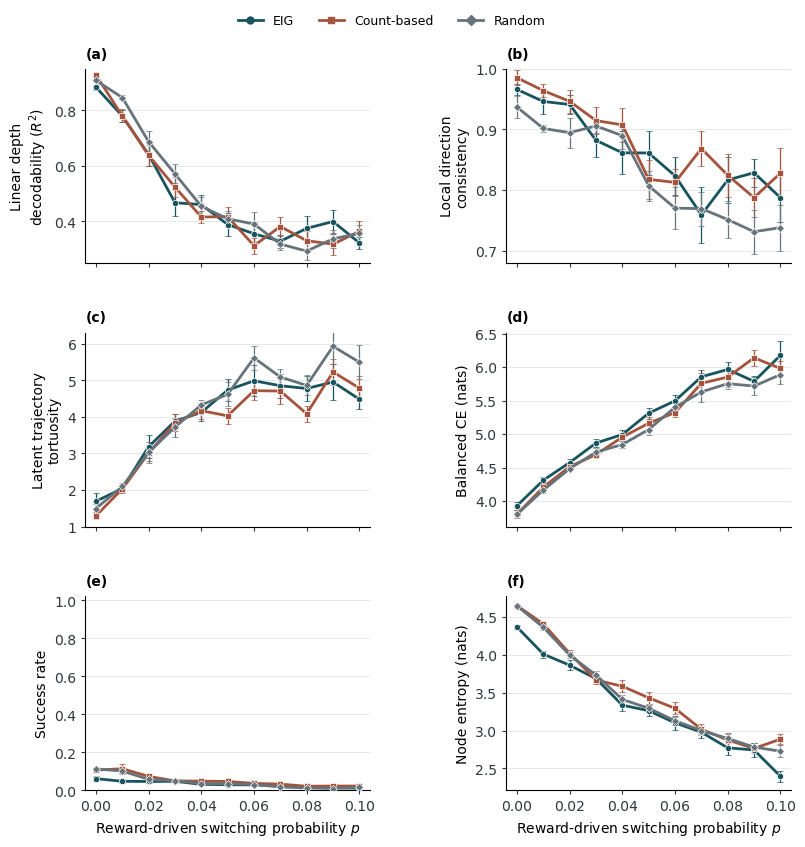

In [8]:

YLIMS = {
    "linear_depth_r2": (0.25, 0.95),
    "transition_consistency": (0.68, 1.00),
    "tortuosity": (1.0, 6.3),
}

stats_list = []

for metric in COMPARE_METRICS:
    stats = (
        strategy_data
        .groupby(["strategy", "p"])[metric]
        .agg(["mean", "sem", "count"])
        .reset_index()
    )

    stats["metric"] = metric
    stats_list.append(stats)

strategy_stats = pd.concat(stats_list, ignore_index=True)

strategy_stats.to_csv(
    FIG5_DIR / "strategy_comparison_mean_sem.csv",
    index=False
)


def plot_strategy_metric(ax, metric):
    data = strategy_stats[
        strategy_stats["metric"] == metric
    ]

    for strategy in STRATEGIES:
        sub = data[
            data["strategy"] == strategy
        ].sort_values("p")

        ax.errorbar(
            sub["p"],
            sub["mean"],
            yerr=sub["sem"].fillna(0),
            color=STRATEGY_COLORS[strategy],
            marker=STRATEGY_MARKERS[strategy],
            linestyle="-",
            markersize=4.5,
            markeredgecolor="white",
            markeredgewidth=0.5,
            linewidth=2.0,
            elinewidth=0.9,
            capsize=2.0,
            capthick=0.9,
            zorder=3
        )

    ax.set_ylabel(COMPARE_METRICS[metric])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="#DFE7E5",
        linewidth=0.6
    )

    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        colors="#30363A"
    )

    ax.set_xlim(
        min(common_p) - 0.004,
        max(common_p) + 0.004
    )
    ax.set_xticks(np.arange(0, 0.101, 0.02))

    if metric == "success_rate":
        ax.set_ylim(0, 1.02)

    if metric in YLIMS:
        ax.set_ylim(*YLIMS[metric])


fig, axes = plt.subplots(
    3, 2,
    figsize=(8.5, 8.8),
    sharex=True
)

flat_axes = axes.flatten()

for i, metric in enumerate(COMPARE_METRICS):
    ax = flat_axes[i]
    plot_strategy_metric(ax, metric)

    ax.set_title(
        f"({chr(97 + i)})",
        loc="left",
        fontsize=10,
        fontweight="bold",
        pad=8
    )

    if i >= 4:
        ax.set_xlabel(
            r"Reward-driven switching probability $p$"
        )

handles = [
    Line2D(
        [0], [0],
        color=STRATEGY_COLORS[name],
        marker=STRATEGY_MARKERS[name],
        linestyle="-",
        linewidth=2,
        markersize=5,
        label=name
    )
    for name in STRATEGIES
]

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=3,
    frameon=False,
    fontsize=9
)

fig.subplots_adjust(
    top=0.91,
    bottom=0.09,
    left=0.14,
    right=0.97,
    wspace=0.48,
    hspace=0.36
)

for ext in ["svg", "pdf", "png"]:
    fig.savefig(
        FIG5_DIR / f"strategy_comparison.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)
